In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Find the project directory
PROJECT_DIR = Path.cwd().parent

# Load  the cleaned dataset
FILE_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "telco_churn_cleaned.csv"
)

df = pd.read_csv(FILE_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv("../data/processed/telco_churn_cleaned.csv")

# Display dataset information
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (7043, 21)

Column Names:
['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents', 'tenure', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod', 'monthlycharges', 'totalcharges', 'churn']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerid        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   seniorcitizen     7043 non-null   int64  
 3   partner           7043 non-null   str    
 4   dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   phoneservice      7043 non-null   str    
 7   multiplelines     7043 non-null   str    
 8   internetservice   7043 non-null   str    


In [6]:
from pathlib import Path
import pandas as pd

# Calculate Overall Customer Churn Rate

# Count total customers

if "df" not in globals():

	candidates = [
		Path.cwd().parent / "data" / "processed" / "telco_churn_cleaned.csv",
		Path("../data/processed/telco_churn_cleaned.csv"),
	]
	for path in candidates:
		if path.exists():
			df = pd.read_csv(path)
			break
	else:
		raise FileNotFoundError("Could not find the cleaned churn dataset.")

total_customers = len(df)

# Use the actual churn column name in the dataset
if "Churn" in df.columns:
	churn_col = "Churn"
elif "churn" in df.columns:
	churn_col = "churn"
else:
	raise KeyError("No churn column found in the DataFrame.")

# Customers who have churned
churned_customers = (df[churn_col].str.upper() == "YES").sum()

# Calculate churn rate
churn_rate = (churned_customers / total_customers) * 100



# Display results
print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print(f"Overall Churn Rate: {churn_rate:.2f}%")

Total Customers: 7043
Churned Customers: 1869
Overall Churn Rate: 26.54%


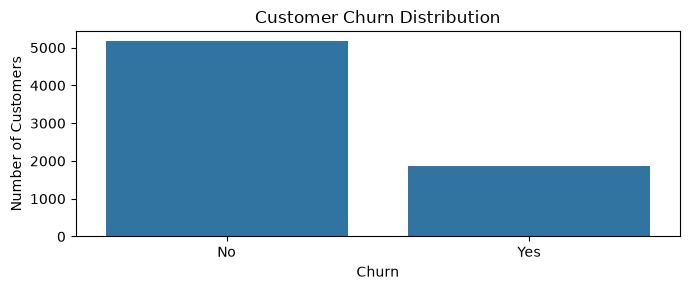

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if "df" not in globals():
	df = pd.read_csv("../data/processed/telco_churn_cleaned.csv")

churn_col = next(
	(column for column in df.columns if column.lower() == "churn"),
	None,
)
if churn_col is None:
	raise KeyError("No churn column found in the DataFrame.")

plt.figure(figsize=(7,3))

sns.countplot(data=df, x=churn_col)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

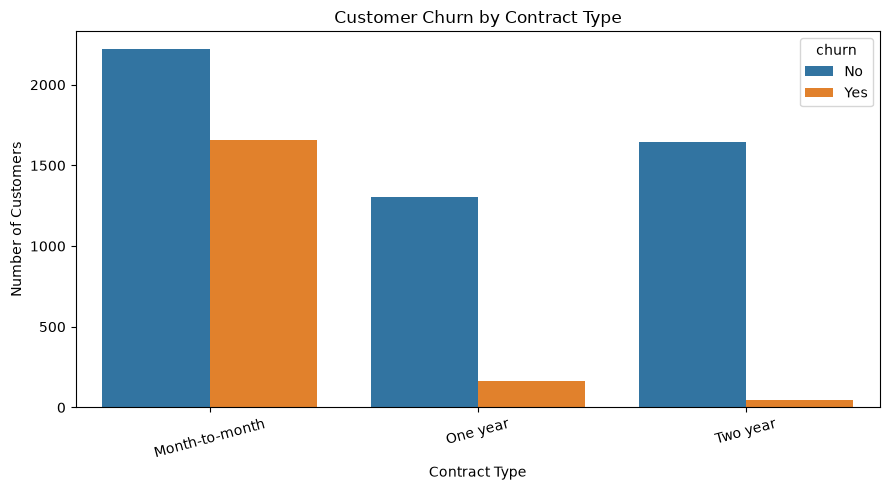

In [19]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="contract", hue=churn_col)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

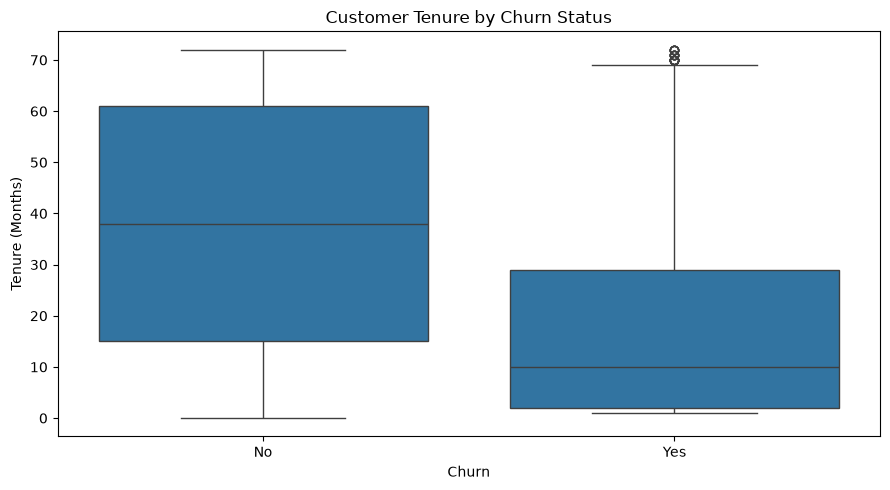

In [21]:

plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x=churn_col, y="tenure")

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()

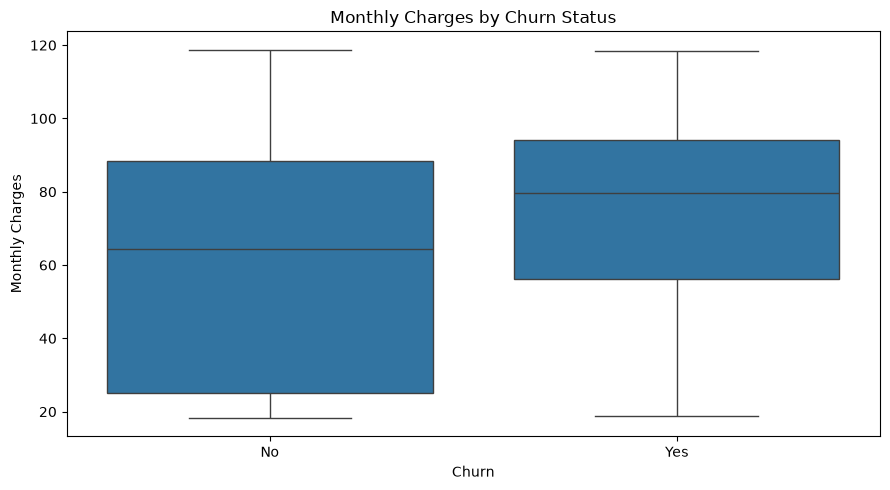

In [23]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x=churn_col, y="monthlycharges")

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

In [5]:
# Find the Contract and Churn columns
contract_col = next(
    (col for col in df.columns if col.lower() == "contract"),
    None
)

churn_col = next(
    (col for col in df.columns if col.lower() == "churn"),
    None
)

if contract_col is None or churn_col is None:
    raise KeyError("Contract or Churn column not found.")

# Calculate churn rate by contract type
contract_analysis = (
    df.groupby(contract_col)[churn_col]
    .apply(lambda x: x.astype(str).str.upper().eq("YES").mean() * 100)
    .reset_index(name="Churn Rate (%)")
)

# Round the results
contract_analysis["Churn Rate (%)"] = (
    contract_analysis["Churn Rate (%)"].round(2)
)

# Display ONLY the final analysis table
display(
    contract_analysis.sort_values(
        "Churn Rate (%)",
        ascending=False
    ).reset_index(drop=True)
)

,contract,Churn Rate (%)
0,Month-to-month,42.71
1,One year,11.27
2,Two year,2.83


In [ ]:
# Churn rate by Internet Service Type

internet_col = "internetservice" if "internetservice" in df.columns else (
    "InternetService" if "InternetService" in df.columns else None
)

if internet_col is None:
    raise KeyError("No internetservice column found in the DataFrame.")

internet_analysis = (
    df.groupby(internet_col)[churn_col]
    .apply(lambda x: x.astype(str).str.upper().eq("YES").mean() * 100)
    .reset_index(name="Churn Rate (%)")
)

internet_analysis["Churn Rate (%)"] = internet_analysis["Churn Rate (%)"].round(2)

print(internet_analysis.sort_values("Churn Rate (%)", ascending=False))

  internetservice  Churn Rate (%)
1     Fiber optic           41.89
0             DSL           18.96
2              No            7.40


In [ ]:
# Churn rate by Payment Method

payment_col = "paymentmethod" if "paymentmethod" in df.columns else (
    "PaymentMethod" if "PaymentMethod" in df.columns else None
)

if payment_col is None:
    raise KeyError("No payment method column found in the DataFrame.")

payment_analysis = (
    df.groupby(payment_col)[churn_col]
    .apply(lambda x: x.astype(str).str.upper().eq("YES").mean() * 100)
    .reset_index(name="Churn Rate (%)")
)

payment_analysis["Churn Rate (%)"] = payment_analysis["Churn Rate (%)"].round(2)

print(payment_analysis.sort_values("Churn Rate (%)", ascending=False))

               paymentmethod  Churn Rate (%)
2           Electronic check           45.29
3               Mailed check           19.11
0  Bank transfer (automatic)           16.71
1    Credit card (automatic)           15.24


In [5]:
import pandas as pd
from pathlib import Path

if "df" not in globals():
    project_dir = Path.cwd().parent
    candidates = [
        project_dir / "data" / "processed" / "telco_churn_cleaned.csv",
        project_dir / "data" / "processed" / "cleaned_churn.csv",
        Path("../data/processed/telco_churn_cleaned.csv"),
        Path("../data/processed/cleaned_churn.csv"),
    ]
    for path in candidates:
        if path.exists():
            df = pd.read_csv(path)
            break
    else:
        raise FileNotFoundError("No churn dataset found in the expected processed data folders.")

# Normalize expected columns to the names used later in this cell
for src, target in {
    "churn": "Churn",
    "contract": "Contract",
    "paymentmethod": "PaymentMethod",
    "monthlycharges": "MonthlyCharges",
}.items():
    matches = [col for col in df.columns if col.lower() == src]
    if matches:
        df = df.rename(columns={matches[0]: target})

# Check dataset size
print("Total customers:", len(df))

# Overall churn analysis
print(df["Churn"].value_counts())

churn_rate = (
    df["Churn"].eq("Yes").mean() * 100
)

print(f"Overall churn rate: {churn_rate:.2f}%")

# Churn rate by contract
print(
    df.groupby("Contract")["Churn"]
      .apply(lambda x: x.eq("Yes").mean() * 100)
      .round(2)
)

# Churn rate by payment method
print(
    df.groupby("PaymentMethod")["Churn"]
      .apply(lambda x: x.eq("Yes").mean() * 100)
      .round(2)
)

# Average monthly charges by churn status
print(
    df.groupby("Churn")["MonthlyCharges"]
      .mean()
      .round(2)
)


Total customers: 7043
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Overall churn rate: 26.54%
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64
PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn, dtype: float64
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


  TenureGroup  ChurnRate
0        0-12      47.44
1       13-24      28.71
2       25-48      20.39
3       49-60      14.42
4       61-72       6.61


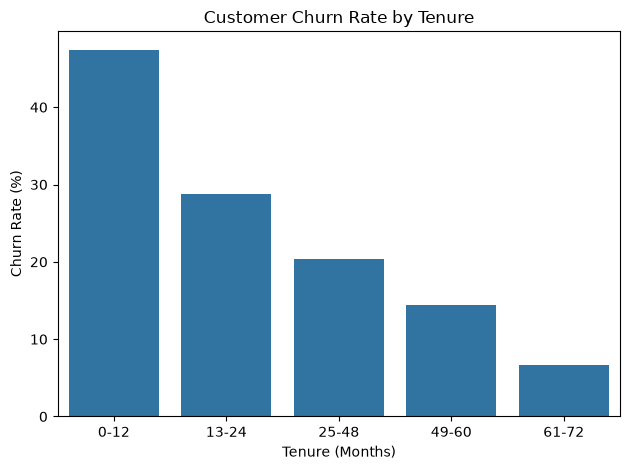

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
# Reuse the dataframe loaded in an earlier cell.
# If it is not available, load the existing cleaned dataset.
if "df" not in globals():
    df = pd.read_csv(
        PROJECT_DIR / "data" / "processed" / "telco_churn_cleaned.csv"
    )

# Group customers by tenure (months)
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=["0-12", "13-24", "25-48", "49-60", "61-72"]
)

# Calculate churn rate for each tenure group
churn_by_tenure = (
    df.groupby("TenureGroup", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

# Display results
print(churn_by_tenure.round(2))

# Plot the results
sns.barplot(data=churn_by_tenure, x="TenureGroup", y="ChurnRate")
plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

In [ ]:
# KEY INSIGHTS AND BUSINESS RECOMMENDATIONS 

# INSIGHT 01 : Month-to-Month Contracts Have the Highest Churn Rate

# Customers on month-to-month contracts are a significant risk for churn. The analysis shows that these customers
# have a much higher churn rate compared to those on one-year or two-year contracts.
# This suggests that customers with longer-term commitments are more likely to stay with the company.

# BUSINESS RECOMMENDATION : To reduce churn, the company should consider offering incentives for customers to switch 
# from month-to-month contracts to longer-term contracts. This could include discounts, added benefits, or loyalty
# rewards for committing to a one-year or two-year contract.

# INSIGHT 02 : Churn is concentrated among newer customers

# CUSTOMER TENURE     |      CHURNED CUSTOMER 

# 0-12 Months                 1,037 
# 13-24 Months                294
# 25-48 Months                325 
# 49+ Months                  213

# The 0-12 Months group has the highest churn rate, indicating that newer customers are more likely to leave
#  the service.
# This could be due to a variety of factors, such as dissatisfaction with the service,
# better offers from competitors, or unmet expectations.

# BUSINESS RECOMMENDATION : The company should focus on improving the onboarding experience for new customers.
# This could include providing better customer support, offering tutorials or guides on how to use the service effectively

# INSIGHT 03 : Churned customers have higher average monthly charges than retained customers

# Churned customers average monthly charges -- $74.44 
# Retained customer average monthly charges -- $61.27

# The average monthly charges for churned customers are significantly higher than those for retained customers. 
# This suggests that high costs may be a contributing factor to customer churn.

# BUSINESS RECOMMENDATION : The company should consider reviewing its pricing strategy. Offering more flexible
# pricing plans or discounts for high-paying customers could help reduce churn. Additionally, the company could
# implement a customer feedback system to understand the reasons behind high charges and address any concerns proactively.

# INSIGHT 04 : Customers with Fiber Optic Internet Service Have the Highest Churn Rate

# The analysis shows that customers with fiber optic internet service have a higher churn rate
# compared to those with DSL or no internet service. This could be due to various factors, such as service reliability,
# customer support issues, or competitive offerings.

# BUSINESS RECOMMENDATION : The company should investigate the reasons behind
# the high churn rate among fiber optic customers.
# This could involve conducting customer surveys, analyzing service performance data,
# and comparing offerings with competitors.

# INSIGHT 05 : Customers Using Electronic Check Payment Method Have the Highest Churn Rate

# The analysis indicates that customers who pay via electronic check have a higher churn rate compared to those using
# other payment methods. This could be due to the convenience of electronic checks, which may make it easier for
# customers to switch providers or cancel services.

# BUSINESS RECOMMENDATION : The company should consider offering incentives for customers to switch to more stable
# payment methods, such as automatic bank transfers or credit card payments. Additionally. 

# INSIGHT 06 : Churn by Gender and Senior Citizen Status

# The analysis shows that there is no significant difference in churn rates between male and female customers.
# However, senior citizens have a slightly higher churn rate compared to non-senior citizens.
# This suggests that age may play a role in customer retention.

# BUSINESS RECOMMENDATION : The company should consider implementing targeted retention strategies for senior
# citizens, such as offering senior discounts, personalized customer support, or services tailored to their needs.